# Lily KG: grounded pretraining, ten epochs

A reproducible first experiment in Lily's toy world. We generate short scenes from explicit rules, verify the answers, publish the data to Hugging Face, download its pinned version, and train the TinyStories architecture from fresh random weights.

This is a fixed shuffled baseline. It does not test curriculum learning or identity.


In [1]:
from pathlib import Path
import sys, json, subprocess
ROOT = Path('/workspace/lily-kg')
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import torch
print('PyTorch:', torch.__version__)
print('GPU:', torch.cuda.get_device_name(0))


PyTorch: 2.8.0+cu128
GPU: NVIDIA RTX PRO 4000 Blackwell


## 1. Define the world

Objects have at most one color and location in each independent scene. Reachability composes through a location. Heavier-than is transitive and asymmetric. Missing evidence produces **Unknown**, unless a declared rule supplies a negative conclusion. Reachability is not grasping.


In [2]:
world=json.loads((ROOT/'world.json').read_text())
print('Entities:', len(world['entities']), 'Seed facts:', len(world['seed_scene']))
print(json.dumps(world['entities'], indent=2))
for rule in world['rules']: print(rule['id']+': '+rule['rule'])
print('Seed facts:',json.dumps(world['seed_scene'][:8],indent=2))


Entities: 22 Seed facts: 35
[
  {
    "id": "lily",
    "type": "agent",
    "label": "Lily"
  },
  {
    "id": "milo",
    "type": "agent",
    "label": "Milo"
  },
  {
    "id": "nora",
    "type": "agent",
    "label": "Nora"
  },
  {
    "id": "theo",
    "type": "agent",
    "label": "Theo"
  },
  {
    "id": "ball",
    "type": "object",
    "label": "ball"
  },
  {
    "id": "apple",
    "type": "object",
    "label": "apple"
  },
  {
    "id": "stone",
    "type": "object",
    "label": "stone"
  },
  {
    "id": "cup",
    "type": "object",
    "label": "cup"
  },
  {
    "id": "toy",
    "type": "object",
    "label": "toy"
  },
  {
    "id": "leaf",
    "type": "object",
    "label": "leaf"
  },
  {
    "id": "stick",
    "type": "object",
    "label": "stick"
  },
  {
    "id": "pear",
    "type": "object",
    "label": "pear"
  },
  {
    "id": "mat",
    "type": "place",
    "label": "mat"
  },
  {
    "id": "table",
    "type": "place",
    "label": "table"
  },
  {
    

## 2. Generate and validate

24,000 training scenes; 1,200 validation scenes; 600 composition tests; 1,200 paired paraphrases. Every question is counterbalanced across Yes/No/Unknown. Composition holds out entity endpoint combinations while keeping their meanings familiar. All text fits within 256 characters.


In [3]:
result=subprocess.run([sys.executable,str(ROOT/'generate.py'),'--out',str(ROOT/'generated')],capture_output=True,text=True,check=True)
print(result.stdout)
result=subprocess.run([sys.executable,str(ROOT/'validate.py'),str(ROOT/'generated')],capture_output=True,text=True,check=True)
print(result.stdout)
examples=[json.loads(line) for line in (ROOT/'generated/validation.jsonl').read_text().splitlines()]
for example in examples[:6]: print(example['task']+'\n'+example['text'])


{
  "version": "v1",
  "seed": 1337,
  "unit": "character tokens, including punctuation and whitespace",
  "training_objective": "full-record next-character cross entropy; first character supplied as context",
  "training_epochs": 10,
  "splits": {
    "train": {
      "records": 24000,
      "characters": 3823235,
      "record_targets": 3799235,
      "max_record_characters": 198,
      "labels": {
        "No": 8000,
        "Yes": 8000,
        "Unknown": 8000
      },
      "tasks": {
        "heavier": 6000,
        "reachable": 6000,
        "color": 6000,
        "on": 6000
      },
      "sha256": "5b26c531f4c74e05d57007ef3af4ff369e0d911f572853048c637d6bf97474a3"
    },
    "validation": {
      "records": 1200,
      "characters": 191105,
      "record_targets": 189905,
      "max_record_characters": 198,
      "labels": {
        "Unknown": 400,
        "Yes": 400,
        "No": 400
      },
      "tasks": {
        "on": 300,
        "reachable": 300,
        "color": 300,


{
  "logic_corner_cases_passed": 9,
  "records_checked": 27000,
  "all_labels_match_symbolic_oracle": true,
  "train_validation_composition_overlap": 0,
  "counterbalanced_question_only_accuracy": 0.3333333333333333,
  "all_records_fit_256_characters": true,
  "paraphrase_policy": "Deliberate paired re-rendering of validation graphs; never trained."
}

on
Facts: The apple is on the table. The stick is red. Nora cannot reach the box. The cup is on the shelf.
Question: Is the stick on the table?
Answer: Unknown.

reachable
Facts: Nora can reach the bench. The ball is on the bench. Milo can reach the table. The apple is on the mat.
Question: Can Milo reach the apple?
Answer: Unknown.

reachable
Facts: The stone is on the shelf. Theo can reach the bench. The apple is on the bench. Milo cannot reach the shelf.
Question: Can Theo reach the apple?
Answer: Yes.

color
Facts: The ball is green. The cup is green. The cup is on the table. Milo cannot reach the bench.
Question: Is the cup gold?
An

## 3. Publish to Hugging Face and pin the training input

Credentials come from the standard HF cache configured on the pod. No credential is stored in the notebook. We verify hashes after downloading the committed dataset. Re-running this cell republishes the deterministic source and data under the same repository.


In [4]:
from publish import publish_dataset
hf_source=publish_dataset(ROOT)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

{
  "repo_id": "chewiesays/lily-kg-mini-v1",
  "revision": "dfbe3515218955f3b737e7cbb3a894be96ffddf1",
  "url": "https://huggingface.co/datasets/chewiesays/lily-kg-mini-v1",
  "manifest_sha256": "08b8e8b181660280b4f6274dbe0af1eb5ce1468a0d8b9dcdffb434640250a251"
}


## 4. Train from scratch for ten epochs

Same six layers, six heads, width 384, context 256, batch 64, dropout 0.2, AdamW learning rate 3e-4, and seed 1337 as the TinyStories baseline. A declared 96-character ASCII alphabet covers unseen wording. Each full scene stays together; right padding has ignored loss.

Primary validation loss scores every held-out scene target. We also report the TinyStories-style estimate: 20 random batches of 64 x 256 character windows per split. Different corpora have different loss scales. Answer accuracy and Unknown recall are evaluated separately. Test sets are first inspected after epoch 10 and checkpoint selection.


In [5]:
from train import train
summary=train(ROOT)


wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.


wandb: Currently logged in as: pipinstallyatharth (peepaclan) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


wandb: setting up run stg4wug8


wandb: Tracking run with wandb version 0.31.0


wandb: Run data is saved locally in /workspace/lily-kg/wandb/run-20261025_144718-stg4wug8
wandb: Run `wandb offline` to turn off syncing.


...

wandb: uploading summary


wandb: 
wandb: Run history:
wandb:                      epoch ▁▂▂▃▄▅▅▆▇▇█
wandb:      loss/tiny_style_train █▂▂▂▃▂▃▂▂▁▃
wandb: loss/tiny_style_validation █▂▂▂▃▂▃▂▂▁▃
wandb:     loss/validation_record █▁▁▁▁▁▁▁▁▁▁
wandb:               targets_seen ▁▂▂▃▄▅▅▆▇▇█
wandb:                    updates ▁▂▂▃▄▅▅▆▇▇█
wandb:  validation/label_accuracy ▁▂▂▂▃▃▄▄▅▆█
wandb:      validation/task_color ▁▁▁▁▂▂▃▄▅▆█
wandb:    validation/task_heavier ▁▂▂▂▃▃▄▅▅▆█
wandb:         validation/task_on ▁▁▁▁▂▂▃▄▄▄█
wandb:                         +2 ...
wandb: 
wandb: Run summary:
wandb:                                  best_epoch 10
wandb:                 best_validation_record_loss 0.12604
wandb:                            completed_epochs 10
wandb:                                       epoch 10
wandb: last/test_composition/greedy_exact_accuracy 0.60333
wandb:        last/test_composition/label_accuracy 0.60333
wandb:  last/test_paraphrase/greedy_exact_accuracy 0.37
wandb:         last/test_paraphrase/label_accuracy 

wandb: 🚀 View run lily-kg-v1-10epochs at: https://forge.coreweave.com/wandb/peepaclan/gpt_train_detour/runs/stg4wug8
wandb: ⭐️ View project at: https://forge.coreweave.com/wandb/peepaclan/gpt_train_detour
wandb: Synced 5 W&B file(s), 0 media file(s), 9 artifact file(s) and 0 other file(s)


wandb: Find logs at: ./wandb/run-20261025_144718-stg4wug8/logs


{
  "completed_epochs": 10,
  "updates": 3750,
  "training_targets_seen": 37992350,
  "best_epoch_by_validation_loss": 10,
  "best_validation_record_loss": 0.12603968578141866,
  "last": {
    "validation": {
      "records": 1200,
      "label_accuracy": 0.7416666666666667,
      "unknown_recall": 0.7925,
      "unknown_precision": 0.8453333333333334,
      "per_task": {
        "color": 0.9333333333333333,
        "heavier": 0.6566666666666666,
        "on": 0.8366666666666667,
        "reachable": 0.54
      },
      "confusion": {
        "Yes": {
          "Yes": 202,
          "No": 146,
          "Unknown": 52
        },
        "No": {
          "Yes": 23,
          "No": 371,
          "Unknown": 6
        },
        "Unknown": {
          "Yes": 65,
          "No": 18,
          "Unknown": 317
        }
      },
      "greedy_exact_answer_accuracy": 0.7416666666666667
    },
    "test_composition": {
      "records": 600,
      "label_accuracy": 0.6033333333333334,
      "unk

## 5. Inspect the learning curve and final tests

The best checkpoint is selected using validation record loss. Final tests include closed-label accuracy using Y/N/U first-character scores and unconstrained greedy exact-answer accuracy. Chance is one-third. Unknown is explicitly taught; success is not evidence of spontaneous abstention.


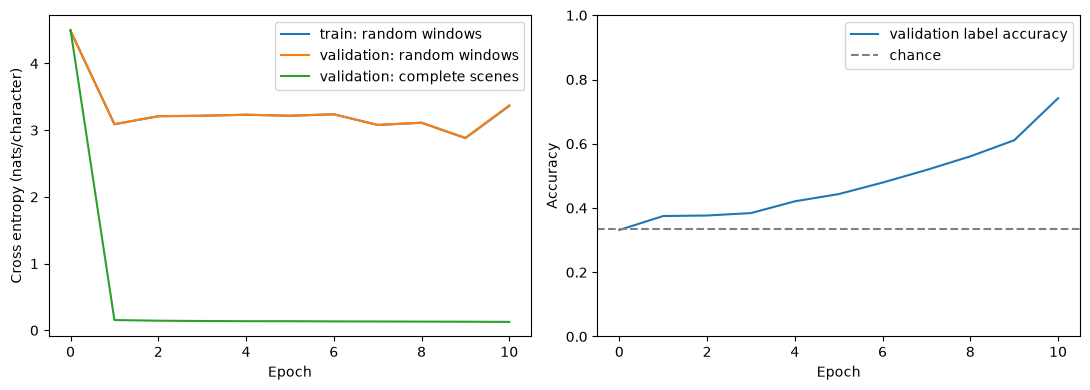

{
  "validation": {
    "records": 1200,
    "label_accuracy": 0.7416666666666667,
    "unknown_recall": 0.7925,
    "unknown_precision": 0.8453333333333334,
    "per_task": {
      "color": 0.9333333333333333,
      "heavier": 0.6566666666666666,
      "on": 0.8366666666666667,
      "reachable": 0.54
    },
    "confusion": {
      "Yes": {
        "Yes": 202,
        "No": 146,
        "Unknown": 52
      },
      "No": {
        "Yes": 23,
        "No": 371,
        "Unknown": 6
      },
      "Unknown": {
        "Yes": 65,
        "No": 18,
        "Unknown": 317
      }
    },
    "greedy_exact_answer_accuracy": 0.7416666666666667
  },
  "test_composition": {
    "records": 600,
    "label_accuracy": 0.6033333333333334,
    "unknown_recall": 0.57,
    "unknown_precision": 0.8837209302325582,
    "per_task": {
      "heavier": 0.6666666666666666,
      "reachable": 0.54
    },
    "confusion": {
      "Yes": {
        "Yes": 77,
        "No": 112,
        "Unknown": 11
      },
 

In [6]:
import matplotlib.pyplot as plt
history=json.loads((ROOT/'out/history.json').read_text())
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot([r['epoch'] for r in history],[r['tiny_style_train_loss'] for r in history],label='train: random windows')
axes[0].plot([r['epoch'] for r in history],[r['tiny_style_validation_loss'] for r in history],label='validation: random windows')
axes[0].plot([r['epoch'] for r in history],[r['validation_record_loss'] for r in history],label='validation: complete scenes')
axes[0].set(xlabel='Epoch',ylabel='Cross entropy (nats/character)');axes[0].legend()
axes[1].plot([r['epoch'] for r in history],[r['validation_label_accuracy'] for r in history],label='validation label accuracy')
axes[1].axhline(1/3,color='gray',linestyle='--',label='chance')
axes[1].set(xlabel='Epoch',ylabel='Accuracy',ylim=(0,1));axes[1].legend()
fig.tight_layout();fig.savefig(ROOT/'out/learning_curves.png',dpi=160);plt.show()
print(json.dumps(summary['last'],indent=2))
print('W&B:',summary['wandb_url'])


In [7]:
predictions=json.loads((ROOT/'out/test_composition_predictions.json').read_text())
for example in predictions[:12]:
    print(example['prompt']+example['greedy_answer'])
    print('Expected:',example['truth'],'| Task:',example['task'],'\n')


Facts: The apple is heavier than the leaf. The leaf is heavier than the cup. The stick is gold. The pear is heavier than the toy.
Question: Is the apple heavier than the stick?
Answer: Unknown
Expected: Unknown | Task: heavier 

Facts: The toy is heavier than the leaf. The pear is heavier than the toy. The ball is gold. The apple is heavier than the stone.
Question: Is the pear heavier than the ball?
Answer: Unknown
Expected: Unknown | Task: heavier 

Facts: Nora can reach the bench. The toy is on the bench. The leaf is on the box. Milo can reach the box.
Question: Can Milo reach the leaf?
Answer: Yes
Expected: Yes | Task: reachable 

Facts: The ball is heavier than the apple. The cup is heavier than the stick. The leaf is heavier than the cup. The stone is red.
Question: Is the leaf heavier than the stone?
Answer: Unknown
Expected: Unknown | Task: heavier 

Facts: Milo cannot reach the table. Nora can reach the log. The pear is on the table. The apple is on the mat.
Question: Can Nora

## First-run interpretation (after evaluation)

Ten epochs completed: 3,750 updates, 37,992,350 character targets, about 6 minutes 42 seconds including evaluation. Epoch ten was the best checkpoint by complete-scene validation loss (4.5036 at initialization to 0.1260).

| Greedy exact answer accuracy | Result |
| --- | ---: |
| Fresh validation scenes, all four tasks | 74.17% |
| Fresh validation scenes, reach/order only | 59.83% |
| Reserved combinations, reach/order only | 60.33% |
| Paired graphs with different wording | 37.00% |

Chance is 33.33%. Composition and the matched validation subset are similar in this single seed. The wording test also introduces eleven unseen word forms, so its result combines lexical and phrasing transfer. Unknown was explicitly supervised. This baseline does not test identity or curriculum benefits.

The final TinyStories-style random-window validation loss is 3.3717. Random windows can cross scene boundaries or begin mid-scene; they differ from complete-scene training. Keep that diagnostic separate from the primary 0.1260 loss. Predictable templates make full-text loss an incomplete measure of answer competence.

[Dataset](https://huggingface.co/datasets/chewiesays/lily-kg-mini-v1) ? [Training run](https://forge.coreweave.com/wandb/peepaclan/gpt_train_detour/runs/stg4wug8) ? [Detailed results](https://github.com/pipinstallyp/gpt_train_detour/tree/main/support/results/lily-kg-v1)
